# data split

In [ ]:
import scanpy as sc

adata = sc.read('../UniPert/perturbation_tasks/chemcial_benchmark/data/processed_sciPlex3.h5ad')
adata

In [14]:
adata.obs['condition'].value_counts()

control         6464
ENMD-2076       2873
GSK-LSD1        1868
BRD4770         1868
Baricitinib     1862
                ... 
AT9283           910
Patupilone       757
Flavopiridol     693
Epothilone       583
YM155            394
Name: condition, Length: 188, dtype: int64

# pathway-based hierarchical leave-drugs-out splitting

In [7]:
adata.obs['pathway_level_1'].value_counts()

pathway_level_1
Epigenetic regulation                    73905
Tyrosine kinase signaling                42804
JAK/STAT signaling                       35507
DNA damage & DNA repair                  30017
Cell cycle regulation                    26952
Nuclear receptor signaling                9974
Other                                     9898
Protein folding & Protein degradation     9579
Metabolic regulation                      8890
Neuronal signaling                        7008
Antioxidant                               6747
Apoptotic regulation                      6629
Vehicle                                   6464
HIF signaling                             4697
PKC signaling                             4460
TGF/BMP signaling                         4425
Focal adhesion signaling                  2932
Name: count, dtype: int64

In [8]:
import pandas as pd

pd.crosstab(adata.obs['pathway_level_1'], adata.obs['condition'])

condition,2-Methoxyestradiol,A-366,ABT-737,AC480,AG-490,AG-14361,AICAR,AMG-900,AR-42,AT9283,...,Valproic,Vandetanib,Veliparib,WHI-P154,WP1066,XAV-939,YM155,ZM,Zileuton,control
pathway_level_1,,,,,,,,,,,,,,,,,,,,,
Antioxidant,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Apoptotic regulation,0,0,1394,0,0,0,0,0,0,0,...,0,0,0,0,0,0,394,0,0,0
Cell cycle regulation,0,0,0,0,0,0,0,1336,0,0,...,0,0,0,0,0,0,0,1394,0,0
DNA damage & DNA repair,0,0,0,0,0,1654,0,0,0,0,...,0,0,1597,0,0,0,0,0,0,0
Epigenetic regulation,0,1681,0,0,0,0,0,0,1406,0,...,1804,0,0,0,0,0,0,0,0,0
Focal adhesion signaling,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
HIF signaling,1487,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
JAK/STAT signaling,0,0,0,0,0,0,0,0,0,910,...,0,0,0,1764,1851,0,0,0,0,0
Metabolic regulation,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1728,0


In [2]:
pathway_key = 'pathway_level_1'
drug_pathway_count = adata.obs.loc[:, [pathway_key, 'condition']].drop_duplicates()[pathway_key]
drug_pathway_count = drug_pathway_count.replace(['NA'], 'Others')
drug_pathway_count = drug_pathway_count.value_counts()
drug_pathway_count = drug_pathway_count.drop(index=['Vehicle'])
drug_pathway_count = drug_pathway_count.reset_index(drop=False)
drug_pathway_count[pathway_key] = drug_pathway_count[pathway_key].astype(str)
drug_pathway_count['pathway(count)'] = drug_pathway_count[pathway_key] + ' (' + drug_pathway_count['count'].astype(str) + ')'
drug_pathway_count

,pathway_level_1,count,pathway(count)
0,Epigenetic regulation,47,Epigenetic regulation (47)
1,Tyrosine kinase signaling,29,Tyrosine kinase signaling (29)
2,JAK/STAT signaling,22,JAK/STAT signaling (22)
3,Cell cycle regulation,21,Cell cycle regulation (21)
4,DNA damage & DNA repair,19,DNA damage & DNA repair (19)
5,Protein folding & Protein degradation,7,Protein folding & Protein degradation (7)
6,Metabolic regulation,6,Metabolic regulation (6)
7,Nuclear receptor signaling,6,Nuclear receptor signaling (6)
8,Other,6,Other (6)
9,Apoptotic regulation,5,Apoptotic regulation (5)


In [3]:
drug_pathway_count['count'].sum()

187

In [4]:
split_pathways = list(drug_pathway_count[pathway_key])[:5]
split_pathways

['Epigenetic regulation',
 'Tyrosine kinase signaling',
 'JAK/STAT signaling',
 'Cell cycle regulation',
 'DNA damage & DNA repair']

In [5]:
drug_pathway_count2 = []
for i in drug_pathway_count['count'].values:
    if i >= 19:
        drug_pathway_count2.extend([int(i*0.8), int(i*0.2)+1])
drug_pathway_count2.extend([sum(drug_pathway_count['count'].values[5:])])
drug_pathway_count2, sum(drug_pathway_count2)

([37, 10, 23, 6, 17, 5, 16, 5, 15, 4, 49], 187)

Current font settings: ['Helvetica']


<Figure size 800x800 with 0 Axes>

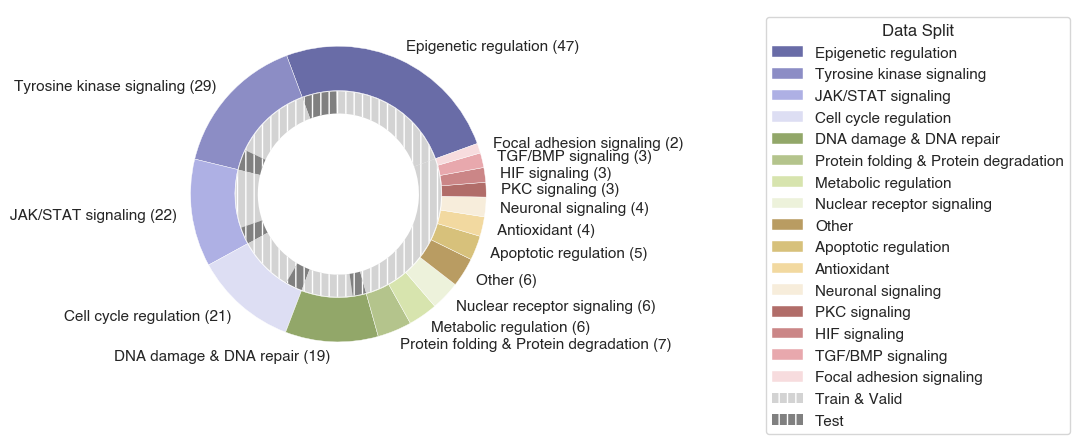

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np


import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.font_manager import FontProperties, fontManager
from matplotlib.ticker import FuncFormatter
import matplotlib.colors as mcolors

sns.set_theme(style="ticks", rc={"axes.facecolor": (0, 0, 0, 0)}, font_scale=1)
font_path = '../Helvetica.ttf' 
fontManager.addfont(font_path)
prop = FontProperties(fname=font_path)
font_name = prop.get_name()
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = [font_name] 
print("Current font settings:", plt.rcParams['font.sans-serif'])


import matplotlib.colors as mcolors
import colorsys

def adjust_lightness(color, amount=0.2, alpha=0.5):
    """
    Lightens the given color by multiplying (1-luminosity) by the given amount.
    Input can be matplotlib color string, hex string, or RGB tuple.
    
    Examples:
    >> adjust_lightness('g', 0.3)
    >> adjust_lightness('#F034A3', 0.6)
    >> adjust_lightness((.3,.55,.1), 0.5)
    """
    try:
        c = mcolors.cnames[color]
    except:
        c = color
    c = colorsys.rgb_to_hls(*mcolors.to_rgb(c))
    return colorsys.hls_to_rgb(c[0], max(0, min(1, amount * c[1])), c[2]), alpha


light_colors = [adjust_lightness(c, 1.2, 0.8) for c in plt.cm.tab20b.colors]
cmap = mcolors.ListedColormap(light_colors)


plt.figure(figsize=(8, 8))
fig, ax = plt.subplots(subplot_kw={'aspect': 'equal'})

ax.pie(
    drug_pathway_count['count'], 
    labels=drug_pathway_count['pathway(count)'],
    colors=cmap(np.arange(22)),
    wedgeprops=dict(width=0.3, edgecolor='w', linewidth=0.3), 
    autopct=None, 
    startangle=20,
    )

ax.pie(
    np.array(drug_pathway_count2), 
    radius=0.695, 
    colors=['lightgray', 'gray']*11,
    wedgeprops=dict(width=0.15, edgecolor='w', linewidth=0.0),
    hatch='||',
    startangle=20,
)

legend_labels = np.array(list(drug_pathway_count[pathway_key])+['Train & Valid', 'Test']).flatten()
ax.legend(legend_labels, title="Data Split", loc='upper right', bbox_to_anchor=(2.5, 1), facecolor='white')

plt.show()



In [ ]:
ood_split = {}
grouped = adata.obs.groupby(pathway_key)
for i in range(5):
    split_key = 'ood_split_' + str(i+1)
    ood_drugs = []
    for pathway, group in grouped:
        if pathway in split_pathways:
            unique_drugs = group['condition'].unique()
            # print(len(unique_drugs))
            np.random.seed(i)
            selected_drugs = np.random.choice(unique_drugs, size=int(0.2*len(unique_drugs))+1, replace=False)
            ood_drugs+=list(selected_drugs)
    # print(ood_drugs)
    ood_split.update({split_key: ood_drugs})
    adata.obs[split_key] = 'train'
    ood_idx = adata[adata.obs['condition'].isin(ood_drugs)].obs.index
    # print(len(ood_drugs), ood_drugs)
    adata.obs[split_key].loc[ood_idx] = 'ood'

    valid_idx = sc.pp.subsample(adata[adata.obs[split_key] != 'ood'], .20, copy=True).obs.index
    adata.obs[split_key].loc[valid_idx] = 'valid'

    adata.uns['ood_split'] = ood_split

In [ ]:
adata.write('/data/liyiming/Project/UniPert-G2CP_reproduce/UniPert/perturbation_tasks/chemcial_benchmark/data/processed_sciPlex3_all.h5ad')